### 시도별 지가와 요양시설 잔여정원 상관관계

본 분석은 '초고령 사회, 서울의 의료·돌봄 인프라는 어디에 더 필요한가?'에서 **땅값이 비싼 지역일수록 요양시설에 남는 자리가 적은가**를 17개 시도 단위로 확인하기 위해 작성되었다.

한국은행(2026) 이슈노트 **별첨 2**는 전국 시군구 패널(2016~2024, N = 2,061)에 공간패널모형을 적용해 '지가가 10% 높을수록 잔여정원 비율이 약 2.3%p 낮다'고 추정했다(그림 3.2). 여기서는 별첨 2와 **같은 모형식·변수 구성·추정법**을 17개 시도 × 2018~2024년 패널에 적용해, 시도 단위에서도 같은 방향의 관계가 나타나는지 점검한다.

### 1. 분석 기준

**모형** — 별첨 2의 공간자기회귀(SAR) 패널모형을 그대로 쓴다.

$$y_{it} = \alpha_i + \lambda \sum_{j=1}^{n} w_{ij}\, y_{jt} + \beta x_{it} + Z_{it}\gamma + \mu_t + \varepsilon_{it}, \qquad i = 1,\dots,17,\quad t = 2018,\dots,2024$$

- $y_{it}$: 잔여정원 비율, $x_{it}$: ln 지가(핵심 요인), $Z_{it}$: 통제변수, $\alpha_i$·$\mu_t$: 시도·연도 고정효과
- $w_{ij}$: 인접 여부만 고려한 공간가중행렬(행 표준화)
- 추정: 최대우도법. 연도 고정효과가 있는 짧은 패널이므로 Lee & Yu(2010)의 변환 우도(two-way 고정효과 제거 후 자유도 $(N-1)(T-1)$ 사용)를 쓰고, 표준오차는 우도함수의 헤시안으로 구한다.

**변수 구성** — 별첨 2 [표 1.1]과 대응

| 분류 | 한국은행 (시군구) | 본 분석 (시도) | 형태 |
|---|---|---|---|
| 노인요양시설 수급 | 잔여정원 비율 = (정원 − 현원) / 장기요양 1~2등급 인정자 수 | 같음. 정원·현원은 노인요양시설 + 노인요양공동생활가정(보건복지부), 1~2등급 인정자는 국민건강보험공단 연말 기준 | level (%) |
| ① 공급 측면 | 종사자 수 | 시설급여 장기요양기관 전문인력 수(국민건강보험공단) | log |
| ② 수요 측면 | 65세 이상 인구 수(단위인구 당) | 65세 이상 인구 비율 = 65세 이상 주민등록인구 / 총인구 × 100 | log |
| | 요양병원 수 | 요양병원 수(보건복지부) | level |
| ③ 핵심 요인 | 지가(㎡당 평균 표준지공시지가) | 같음. 해당 연도 1월 1일 공시 기준 시도 평균 | log |
| ④ 지역 고유 특성 | 고정효과(two-way) | 같음 | |
| ⑤ 주변 지역 영향 | 인접 시군구의 잔여정원 비율 | 인접 시도의 잔여정원 비율 | level |

**별첨 2와 다른 점**

- 분석 단위가 시군구(약 229개)에서 시도(17개)로 바뀌어 관측치가 2,061개에서 119개로 줄어든다.
- 기간은 2018~2024년이다. 시도별 노인요양시설 **현원**을 공개하는 보건복지부 자료가 2018년부터 있다.
- 시도 경계를 기준으로 인접 여부를 정했다. 제주는 육지 경계가 없어 가장 가까운 전남과 인접한 것으로 둔다(7절에서 제주를 빼고 다시 추정).

**자료 위치** — 표준지공시지가(연도별 50~58만 필지, 각 70~170MB)는 공공데이터포털에서 내려받아 `assets/`에 캐시하며 git에는 올리지 않는다. KOSIS 자료는 상위 폴더 `.env`의 `KOSIS_API_KEY`로 한 번 내려받아 `assets/`에 CSV로 저장하므로, 이후에는 키 없이 재실행할 수 있다. 결과는 `outputs/`에 저장한다.

In [1]:
from pathlib import Path
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from IPython.display import display, Markdown
from scipy import stats
from scipy.optimize import minimize_scalar
from statsmodels.tools.numdiff import approx_hess

pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["font.family"] = ["AppleGothic", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

ASSET_DIR = Path("assets")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
ENV_FILE = Path("..") / ".env"

YEARS = list(range(2018, 2025))
SIDO = ["서울", "부산", "대구", "인천", "광주", "대전", "울산", "세종",
        "경기", "강원", "충북", "충남", "전북", "전남", "경북", "경남", "제주"]
SIDO_ALIAS = {
    "서울특별시": "서울", "부산광역시": "부산", "대구광역시": "대구", "인천광역시": "인천",
    "광주광역시": "광주", "대전광역시": "대전", "울산광역시": "울산", "세종특별자치시": "세종",
    "경기도": "경기", "강원도": "강원", "강원특별자치도": "강원", "충청북도": "충북", "충청남도": "충남",
    "전라북도": "전북", "전북특별자치도": "전북", "전라남도": "전남",
    "경상북도": "경북", "경상남도": "경남", "제주특별자치도": "제주",
}

# 공공데이터포털 '국토교통부_표준지공시지가'(15004246) 연도별 이력 파일
LAND_FILE_IDS = {
    2018: ("FILE_000000002292248", "csv"), 2019: ("FILE_000000002292431", "csv"),
    2020: ("FILE_000000002484654", "csv"), 2021: ("FILE_000000002487665", "csv"),
    2022: ("FILE_000000002631907", "zip"), 2023: ("FILE_000000002757328", "csv"),
    2024: ("FILE_000000002945598", "csv"),
}
FACILITY_FILE = ASSET_DIR / "보건복지부_노인복지 생활시설 수 및 생활자 현황_시설 종류별_시도별_20241231.csv"
HOSPITAL_FILE = ASSET_DIR / "보건복지부_병원 및 의원 수_의료기관 종류별_시도별_20241231.csv"

### 2. 자료 수집

- **잔여정원**: 보건복지부 '노인복지 생활시설 수 및 생활자 현황'(시도별, 2018~2024)의 노인요양시설·노인요양공동생활가정 정원과 현원
- **1~2등급 인정자, 시설 종사자**: KOSIS 국민건강보험공단 노인장기요양보험통계 — `시·도별 등급별 연령별 자격별 등급 판정 현황`(DT_35006_N036), `시·군·구별 장기요양기관 인력 현황`(DT_35006_N022, 급여종류 '시설')
- **65세 이상 인구**: KOSIS 행정안전부 `행정구역(읍면동)별/5세별 주민등록인구`(DT_1B04005N, 연말)
- **요양병원 수**: 보건복지부 '병원 및 의원 수_의료기관 종류별_시도별'
- **지가**: 국토교통부 표준지공시지가 연도별 이력 파일

In [2]:
KOSIS_SIDO = {f"15350AC400{c}": s for c, s in zip(
    "A1 B1 C1 D1 E1 F1 G1 G2 H1 I1 J1 K1 L1 M1 N1 O1 P1".split(), SIDO)}
POP_SIDO = {c: s for c, s in zip(
    "11 26 27 28 29 30 31 36 41 51 43 44 52 46 47 48 50".split(), SIDO)}


def kosis_key():
    key = os.environ.get("KOSIS_API_KEY")
    if not key and ENV_FILE.exists():
        for line in ENV_FILE.read_text().splitlines():
            if line.startswith("KOSIS_API_KEY="):
                key = line.split("=", 1)[1].strip().strip("'\"")
    assert key, "KOSIS_API_KEY가 필요합니다(.env 또는 환경변수)"
    return key


def kosis(cache_name, org, tbl, **params):
    """KOSIS 통계자료를 한 번 내려받아 assets/에 CSV로 캐시한다."""
    path = ASSET_DIR / cache_name
    if not path.exists():
        query = dict(method="getList", apiKey=kosis_key(), format="json", jsonVD="Y",
                     orgId=org, tblId=tbl, prdSe="Y",
                     startPrdDe=str(YEARS[0]), endPrdDe=str(YEARS[-1]), **params)
        # 여러 코드를 '+'로 잇는 KOSIS 형식이라 '+'를 인코딩하지 않는다
        url = "https://kosis.kr/openapi/Param/statisticsParameterData.do?" + "&".join(
            f"{k}={requests.utils.quote(str(v), safe='+')}" for k, v in query.items())
        rows = requests.get(url, timeout=120).json()
        assert isinstance(rows, list), rows
        cols = ["PRD_DE", *[f"C{i}{s}" for i in range(1, 9) for s in ("", "_NM")], "ITM_NM", "DT"]
        pd.DataFrame(rows)[[c for c in cols if c in rows[0]]].to_csv(
            path, index=False, encoding="utf-8-sig")
    out = pd.read_csv(path, dtype={f"C{i}": str for i in range(1, 9)})
    out["연도"] = out["PRD_DE"].astype(int)
    out["DT"] = pd.to_numeric(out["DT"], errors="coerce")
    return out


sido_codes = "+".join(KOSIS_SIDO)

grade = kosis("KOSIS_장기요양_1_2등급_인정자_시도_2018_2024.csv", "350", "DT_35006_N036",
              itmId="T001", objL1=sido_codes, objL2="001", objL3="001",
              objL4="36006A001", objL5="00102+00103")
grade["시도"] = grade["C1"].map(KOSIS_SIDO)
severe = grade.groupby(["연도", "시도"], as_index=False)["DT"].sum().rename(columns={"DT": "중증_1_2등급"})

staff = kosis("KOSIS_장기요양기관_시설급여_전문인력_시도_2018_2024.csv", "350", "DT_35006_N022",
              itmId="001", objL1=sido_codes, objL2="ALL", objL3="350060A03")
staff["시도"] = staff["C1"].map(KOSIS_SIDO)
staff = staff.groupby(["연도", "시도"], as_index=False)["DT"].sum().rename(columns={"DT": "종사자수"})

pop = kosis("KOSIS_주민등록인구_시도_65세이상_2018_2024.csv", "101", "DT_1B04005N",
            itmId="T2", objL1="+".join(POP_SIDO), objL2="0+70+75+80+85+90+95+100+105")
pop["시도"] = pop["C1"].map(POP_SIDO)
pop["구분"] = np.where(pop["C2"].eq("0"), "총인구", "고령인구_65세이상")
pop = pop.pivot_table(index=["연도", "시도"], columns="구분", values="DT", aggfunc="sum").reset_index()
pop.columns.name = None

for frame in (severe, staff, pop):
    assert len(frame) == 17 * len(YEARS) and frame["시도"].notna().all()

In [3]:
def to_short(name):
    """'서울Seoul', '서울 Seoul' 같은 표기를 '서울'로 맞춘다."""
    return next(s for s in SIDO if str(name).startswith(s))


facility_raw = pd.read_csv(FACILITY_FILE)
facility = pd.DataFrame({
    "연도": facility_raw["연도"],
    "시도": facility_raw["시도"].map(to_short),
    "정원": facility_raw["노인의료복지시설_노인요양시설_정원"] + facility_raw["노인의료복지시설_노인요양공동생활가정_정원"],
    "현원": facility_raw["노인의료복지시설_노인요양시설_현원"] + facility_raw["노인의료복지시설_노인요양공동생활가정_현원"],
})

hospital_raw = pd.read_csv(HOSPITAL_FILE)
hospital = pd.DataFrame({
    "연도": hospital_raw["연도"],
    "시도": hospital_raw["시도"].map(to_short),
    "요양병원수": hospital_raw["병의원_요양병원"],
})


def land_file(year):
    file_id, ext = LAND_FILE_IDS[year]
    path = ASSET_DIR / f"국토교통부_표준지공시지가_{year}0101.{ext}"
    if not path.exists():
        url = ("https://www.data.go.kr/cmm/cmm/fileDownload.do"
               f"?atchFileId={file_id}&fileDetailSn=1&insertDataPrcus=N")
        with requests.get(url, stream=True, timeout=1800) as response:
            response.raise_for_status()
            with open(path, "wb") as f:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    return path


land_frames = []
for year in YEARS:
    path = land_file(year)
    encoding = "cp949" if year <= 2020 else "utf-8-sig"  # 2021년 파일부터 UTF-8
    parcels = pd.read_csv(path, encoding=encoding, usecols=["시도명", "지목", "공시지가"])
    parcels["시도"] = parcels["시도명"].map(SIDO_ALIAS)
    assert parcels["시도"].notna().all() and (parcels["공시지가"] > 0).all()
    summary = parcels.groupby("시도").agg(
        표준지수=("공시지가", "size"), 평균_지가=("공시지가", "mean"), 중위_지가=("공시지가", "median"))
    summary["대지_평균_지가"] = parcels.loc[parcels["지목"].eq("대")].groupby("시도")["공시지가"].mean()
    land_frames.append(summary.reset_index().assign(연도=year))
land = pd.concat(land_frames, ignore_index=True)

display(land.pivot(index="시도", columns="연도", values="평균_지가").loc[SIDO].div(1e4)
        .style.format("{:,.1f}").set_caption("㎡당 평균 표준지공시지가(만원)"))

연도,2018,2019,2020,2021,2022,2023,2024
시도,,,,,,,
서울,498.8,555.6,590.3,650.8,716.4,671.0,677.9
부산,144.2,161.8,171.6,188.0,206.5,193.6,193.7
대구,96.7,106.2,113.7,124.6,136.5,127.8,108.9
인천,96.8,100.7,104.9,112.7,120.3,112.9,112.9
광주,53.9,58.5,62.6,69.6,75.4,71.0,71.0
대전,77.6,80.8,84.6,90.9,98.0,92.3,92.7
울산,63.6,67.9,69.6,73.9,77.8,72.2,71.2
세종,25.8,28.9,30.6,34.1,36.8,34.9,35.2
경기,68.2,71.9,75.5,82.3,87.1,82.0,82.4


### 3. 패널 구성

In [4]:
keys = ["연도", "시도"]
panel = (facility.merge(severe, on=keys, validate="one_to_one")
         .merge(staff, on=keys, validate="one_to_one")
         .merge(pop, on=keys, validate="one_to_one")
         .merge(hospital, on=keys, validate="one_to_one")
         .merge(land, on=keys, validate="one_to_one"))
panel = panel.loc[panel["연도"].isin(YEARS)].sort_values(keys).reset_index(drop=True)
assert len(panel) == 17 * len(YEARS) and not panel.isna().any().any()

panel["잔여정원"] = panel["정원"] - panel["현원"]
panel["잔여정원_비율"] = panel["잔여정원"] / panel["중증_1_2등급"] * 100
panel["가동률"] = panel["현원"] / panel["정원"] * 100
panel["고령인구_비율"] = panel["고령인구_65세이상"] / panel["총인구"] * 100
panel["ln_종사자수"] = np.log(panel["종사자수"])
panel["ln_고령인구_비율"] = np.log(panel["고령인구_비율"])
for col in ["평균_지가", "중위_지가", "대지_평균_지가"]:
    panel[f"ln_{col}"] = np.log(panel[col])
panel.to_csv(OUTPUT_DIR / "시도별_패널_2018_2024.csv", index=False, encoding="utf-8-sig")

display(panel.pivot(index="시도", columns="연도", values="잔여정원_비율").loc[SIDO]
        .style.format("{:.1f}").background_gradient(cmap="Blues", axis=None)
        .set_caption("잔여정원 비율(장기요양 1~2등급 인정자 대비, %)"))

describe_cols = {"잔여정원_비율": "잔여정원 비율(%)", "종사자수": "시설 종사자 수(명)",
                 "고령인구_비율": "65세 이상 인구 비율(%)", "요양병원수": "요양병원 수(개)",
                 "평균_지가": "㎡당 평균 지가(원)"}
display(panel[list(describe_cols)].rename(columns=describe_cols).describe().T
        [["mean", "std", "min", "max"]].style.format("{:,.1f}").set_caption("기술통계 (N = 119)"))

연도,2018,2019,2020,2021,2022,2023,2024
시도,,,,,,,
서울,2.8,2.5,6.8,7.5,7.5,6.1,6.1
부산,13.0,13.5,15.6,17.2,18.5,14.5,15.7
대구,12.0,10.8,16.9,22.9,31.4,22.4,19.0
인천,17.4,17.8,41.7,39.5,47.9,46.0,43.6
광주,27.2,22.7,23.7,28.7,31.8,28.0,21.0
대전,27.2,25.7,30.7,39.8,47.6,46.9,32.7
울산,10.0,25.4,19.0,11.3,11.9,17.5,18.5
세종,22.5,16.6,23.9,19.8,27.5,32.9,20.2
경기,11.9,22.5,36.8,44.4,54.4,52.3,45.2


,mean,std,min,max
잔여정원 비율(%),25.1,10.7,2.5,54.4
시설 종사자 수(명),"6,344.2","8,001.6",228.0,"46,606.0"
65세 이상 인구 비율(%),17.8,4.1,9.3,27.2
요양병원 수(개),84.3,69.5,3.0,320.0
㎡당 평균 지가(원),"875,445.1","1,436,864.4","66,921.3","7,164,054.0"


### 4. 공간가중행렬

별첨 2와 같이 경계를 맞대고 있는지만 따진다(행 표준화). 제주는 육지 경계가 없어 가장 가까운 전남과 인접한 것으로 둔다.

In [5]:
ADJACENT = {
    "서울": ["인천", "경기"], "부산": ["울산", "경남"], "대구": ["경북", "경남"], "인천": ["서울", "경기"],
    "광주": ["전남"], "대전": ["세종", "충북", "충남"], "울산": ["부산", "경북", "경남"],
    "세종": ["대전", "충북", "충남"], "경기": ["서울", "인천", "강원", "충북", "충남"],
    "강원": ["경기", "충북", "경북"], "충북": ["경기", "강원", "대전", "세종", "충남", "전북", "경북"],
    "충남": ["경기", "대전", "세종", "충북", "전북"], "전북": ["충북", "충남", "전남", "경북", "경남"],
    "전남": ["광주", "전북", "경남", "제주"], "경북": ["대구", "울산", "강원", "충북", "전북", "경남"],
    "경남": ["부산", "대구", "울산", "전북", "전남", "경북"], "제주": ["전남"],
}


def weight_matrix(regions):
    W = np.array([[float(b in ADJACENT[a]) for b in regions] for a in regions])
    assert (W == W.T).all() and (W.sum(1) > 0).all()
    return W / W.sum(1, keepdims=True)


W = weight_matrix(SIDO)
print(f"인접 쌍 {int((W > 0).sum() / 2)}개, 시도당 평균 인접 수 {(W > 0).sum(1).mean():.1f}")

인접 쌍 30개, 시도당 평균 인접 수 3.5


### 5. 공간패널모형 추정

In [6]:
def two_way_demean(a):
    """(연도, 시도[, 변수]) 배열에서 시도·연도 평균을 제거한다."""
    return a - a.mean(0, keepdims=True) - a.mean(1, keepdims=True) + a.mean((0, 1), keepdims=True)


def sar_panel(data, y, xs, regions, W, lee_yu=True):
    """시도·연도 고정효과 공간자기회귀 패널모형의 최대우도 추정.

    lee_yu=True: Lee & Yu(2010) 변환 우도(자유도 (N-1)(T-1), 연도 효과 보정)
    lee_yu=False: 고정효과를 빼고 일반 우도를 쓰는 직접 접근(spreg Panel_FE_Lag + 연도 더미와 같음)
    """
    wide = data.set_index(["연도", "시도"]).sort_index()
    Y = wide[y].unstack()[regions].to_numpy()                                  # T x N
    X = np.stack([wide[x].unstack()[regions].to_numpy() for x in xs], axis=-1)  # T x N x K
    T, N = Y.shape
    ys = two_way_demean(Y).ravel()
    wys = two_way_demean(Y @ W.T).ravel()
    Xs = two_way_demean(X).reshape(-1, len(xs))

    omega = np.linalg.eigvals(W).real
    n_eff = (N - 1) * (T - 1) if lee_yu else N * (T - 1)

    def log_det(lam):
        return (T - 1) * (np.log(1 - lam * omega).sum() - (np.log(1 - lam) if lee_yu else 0))

    # 집중 우도: β(λ) = b0 − λ·b1
    b0 = np.linalg.lstsq(Xs, ys, rcond=None)[0]
    b1 = np.linalg.lstsq(Xs, wys, rcond=None)[0]
    e0, e1 = ys - Xs @ b0, wys - Xs @ b1

    def neg_concentrated(lam):
        e = e0 - lam * e1
        return n_eff / 2 * np.log(e @ e / n_eff) - log_det(lam)

    lam = minimize_scalar(neg_concentrated, bounds=(1 / omega.min() + 1e-6, 1 - 1e-6), method="bounded").x
    beta = b0 - lam * b1
    resid = ys - lam * wys - Xs @ beta
    sigma2 = resid @ resid / n_eff

    def loglik(theta):
        b, l, s2 = theta[:-2], theta[-2], theta[-1]
        r = ys - l * wys - Xs @ b
        return -n_eff / 2 * np.log(2 * np.pi * s2) - r @ r / (2 * s2) + log_det(l)

    theta = np.r_[beta, lam, sigma2]
    se = np.sqrt(np.diag(np.linalg.inv(-approx_hess(theta, loglik))))
    table = pd.DataFrame({"계수": theta[:-1], "표준오차": se[:-1]}, index=[*xs, "인접_잔여정원_비율"])
    table["p"] = 2 * stats.norm.sf((table["계수"] / table["표준오차"]).abs())
    y_all = Y.ravel()
    fit = {"N": N, "T": T, "관측치": N * T,
           "R2": 1 - resid @ resid / ((y_all - y_all.mean()) @ (y_all - y_all.mean())),
           "R2_within": 1 - resid @ resid / (ys @ ys), "로그우도": loglik(theta)}
    return table, fit


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


CONTROLS = ["ln_종사자수", "ln_고령인구_비율", "요양병원수"]
main, main_fit = sar_panel(panel, "잔여정원_비율", [*CONTROLS, "ln_평균_지가"], SIDO, W)
main.to_csv(OUTPUT_DIR / "시도별_공간패널_추정결과.csv", encoding="utf-8-sig")

LABELS = {"ln_종사자수": "종사자 수", "ln_고령인구_비율": "65세 이상 인구 비율", "요양병원수": "요양병원 수",
          "ln_평균_지가": "지가(地價)", "인접_잔여정원_비율": "인접 지역의 공급여력"}
BOK = {"ln_종사자수": (10.7657, 1.7909, "***"), "ln_고령인구_비율": (-31.7764, 7.3494, "***"),
       "요양병원수": (1.4946, 0.2862, "***"), "ln_평균_지가": (-22.8208, 4.2117, "***"),
       "인접_잔여정원_비율": (0.1219, 0.0298, "***")}

rows = []
for key, label in LABELS.items():
    r = main.loc[key]
    rows.append({"변수": label,
                 "본 분석 (시도, 2018~2024)": f"{r['계수']:.4f}{stars(r['p'])}  ({r['표준오차']:.4f})",
                 "한국은행 별첨 2 (시군구, 2016~2024)": f"{BOK[key][0]:.4f}{BOK[key][2]}  ({BOK[key][1]:.4f})"})
rows += [{"변수": "개별 및 시간 고정효과", "본 분석 (시도, 2018~2024)": "Yes", "한국은행 별첨 2 (시군구, 2016~2024)": "Yes"},
         {"변수": "N", "본 분석 (시도, 2018~2024)": f"{main_fit['관측치']}", "한국은행 별첨 2 (시군구, 2016~2024)": "2,061"},
         {"변수": "R-sq", "본 분석 (시도, 2018~2024)": f"{main_fit['R2']:.3f} (within {main_fit['R2_within']:.3f})",
          "한국은행 별첨 2 (시군구, 2016~2024)": "0.738"}]
display(pd.DataFrame(rows).style.hide(axis="index").set_caption(
    "[표 1.2 대응] 공간패널모형 추정 결과 — 종속변수: 잔여정원 비율. ( ) 표준오차, *, **, *** 10%, 5%, 1% 유의"))

land_coef, rho = main.loc["ln_평균_지가"], main.loc["인접_잔여정원_비율"]
display(Markdown(
    f"- 지가가 10% 높으면 잔여정원 비율이 **{abs(land_coef['계수']) * np.log(1.1):.1f}%p** 낮다"
    f"(계수 {land_coef['계수']:.2f}, p = {land_coef['p']:.2f}). 한국은행 추정치는 2.2%p(본문 표기 약 2.3%p)다.\n"
    f"- 인접 시도의 잔여정원 비율이 10%p 낮아지면 해당 시도의 잔여정원 비율도 **{rho['계수'] * 10:.1f}%p** 낮아진다"
    f"(λ = {rho['계수']:.3f}, p = {rho['p']:.3f}). 한국은행은 1.2%p다."
))

변수,"본 분석 (시도, 2018~2024)","한국은행 별첨 2 (시군구, 2016~2024)"
종사자 수,26.5103*** (8.9521),10.7657*** (1.7909)
65세 이상 인구 비율,-23.0448 (23.1442),-31.7764*** (7.3494)
요양병원 수,0.1207 (0.1333),1.4946*** (0.2862)
지가(地價),-20.7352 (14.6815),-22.8208*** (4.2117)
인접 지역의 공급여력,0.2696** (0.1052),0.1219*** (0.0298)
개별 및 시간 고정효과,Yes,Yes
N,119,"2,061"
R-sq,0.831 (within 0.155),0.738


- 지가가 10% 높으면 잔여정원 비율이 **2.0%p** 낮다(계수 -20.74, p = 0.16). 한국은행 추정치는 2.2%p(본문 표기 약 2.3%p)다.
- 인접 시도의 잔여정원 비율이 10%p 낮아지면 해당 시도의 잔여정원 비율도 **2.7%p** 낮아진다(λ = 0.270, p = 0.010). 한국은행은 1.2%p다.

### 6. 시각화: 그림 3.2 형식

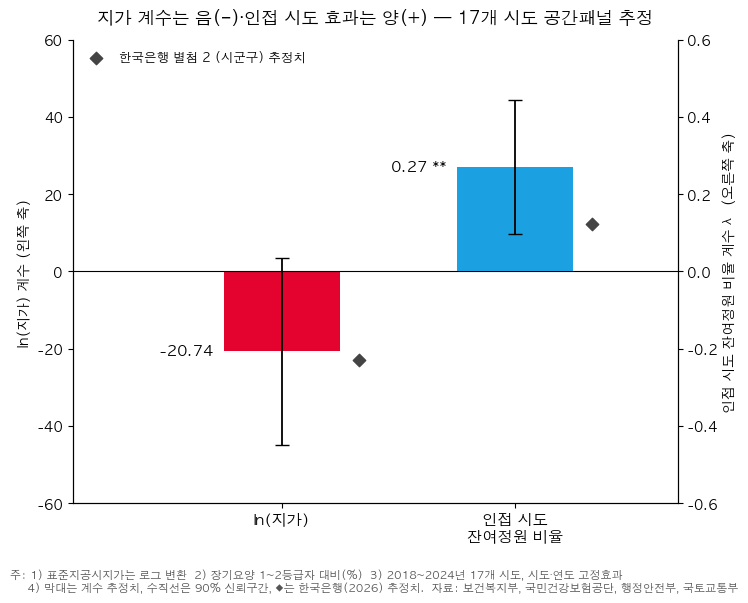

In [7]:
Z90 = stats.norm.ppf(0.95)
LAND_COLOR, RHO_COLOR = "#E4032E", "#1BA1E2"

fig, ax_land = plt.subplots(figsize=(7.5, 6))
ax_rho = ax_land.twinx()
bars = [(ax_land, 0, main.loc["ln_평균_지가"], LAND_COLOR, BOK["ln_평균_지가"][0]),
        (ax_rho, 1, main.loc["인접_잔여정원_비율"], RHO_COLOR, BOK["인접_잔여정원_비율"][0])]
for ax, x, row, color, bok in bars:
    half = Z90 * row["표준오차"]
    ax.bar(x, row["계수"], width=0.5, color=color, zorder=2)
    ax.errorbar(x, row["계수"], yerr=half, color="black", linewidth=1.3, capsize=5, zorder=3)
    ax.scatter(x + 0.33, bok, marker="D", s=40, color="#444444", zorder=4)
    ax.annotate(f"{row['계수']:.2f} {stars(row['p'])}".strip(), (x - 0.27, row["계수"]),
                xytext=(-4, 0), textcoords="offset points", ha="right", va="center",
                fontsize=11, fontweight="bold")

ax_land.set_ylim(-60, 60)
ax_rho.set_ylim(-0.6, 0.6)
ax_land.axhline(0, color="black", linewidth=0.8)
ax_land.set_xticks([0, 1])
ax_land.set_xticklabels(["ln(지가)", "인접 시도\n잔여정원 비율"], fontsize=11)
ax_land.set_xlim(-0.9, 1.7)
ax_land.set_ylabel("ln(지가) 계수 (왼쪽 축)")
ax_rho.set_ylabel("인접 시도 잔여정원 비율 계수 λ (오른쪽 축)")
for ax in (ax_land, ax_rho):
    ax.spines[["top"]].set_visible(False)
ax_land.scatter([], [], marker="D", s=40, color="#444444", label="한국은행 별첨 2 (시군구) 추정치")
ax_land.legend(loc="upper left", frameon=False, fontsize=9)
ax_land.set_title("지가 계수는 음(−)·인접 시도 효과는 양(+) — 17개 시도 공간패널 추정", fontsize=12.5, pad=12)
fig.text(0.01, 0.005,
         "주: 1) 표준지공시지가는 로그 변환  2) 장기요양 1~2등급자 대비(%)  3) 2018~2024년 17개 시도, 시도·연도 고정효과\n"
         "     4) 막대는 계수 추정치, 수직선은 90% 신뢰구간, ◆는 한국은행(2026) 추정치.  "
         "자료: 보건복지부, 국민건강보험공단, 행정안전부, 국토교통부",
         fontsize=8, color="#555555")
plt.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(OUTPUT_DIR / "시도별_공간패널_그림3.2.png", dpi=200, bbox_inches="tight")
plt.show()

### 7. 강건성 점검

관측치가 119개뿐이므로 다음을 바꿔 가며 지가 계수의 방향과 크기가 유지되는지 본다.

- **추정법**: 공간항을 뺀 이원고정효과 OLS(시도 군집 강건 표준오차), 공간항은 두되 Lee–Yu 보정 없이 고정효과만 제거한 직접 접근
- **지가 지표**: 평균 / 중위 / 대지(지목 '대') 평균
- **표본**: 서울 제외, 제주 제외(제주–전남 인접 가정의 영향 확인)

In [8]:
def ols_fe(data, y, xs):
    formula = f"{y} ~ {' + '.join(xs)} + C(시도) + C(연도)"
    fit = smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["시도"]})
    x = xs[-1]
    return {"계수": fit.params[x], "표준오차": fit.bse[x], "p": fit.pvalues[x], "λ": np.nan, "λ_p": np.nan}


def sar_row(data, y, xs, regions, **kw):
    table, _ = sar_panel(data, y, xs, regions, weight_matrix(regions), **kw)
    r, l = table.loc[xs[-1]], table.loc["인접_잔여정원_비율"]
    return {"계수": r["계수"], "표준오차": r["표준오차"], "p": r["p"], "λ": l["계수"], "λ_p": l["p"]}


def without(name):
    regions = [s for s in SIDO if s != name]
    return panel.loc[panel["시도"].ne(name)], regions


saved_adjacency = {k: list(v) for k, v in ADJACENT.items()}
specs = {}
specs["기본 모형 (SAR, Lee–Yu)"] = sar_row(panel, "잔여정원_비율", [*CONTROLS, "ln_평균_지가"], SIDO)
specs["SAR 직접 접근"] = sar_row(panel, "잔여정원_비율", [*CONTROLS, "ln_평균_지가"], SIDO, lee_yu=False)
specs["이원고정효과 OLS (공간항 없음)"] = ols_fe(panel, "잔여정원_비율", [*CONTROLS, "ln_평균_지가"])
specs["지가 지표: 중위 지가"] = sar_row(panel, "잔여정원_비율", [*CONTROLS, "ln_중위_지가"], SIDO)
specs["지가 지표: 대지 평균 지가"] = sar_row(panel, "잔여정원_비율", [*CONTROLS, "ln_대지_평균_지가"], SIDO)
for name in ["서울", "제주"]:
    data, regions = without(name)
    for k in ADJACENT:  # 빠진 시도를 인접 목록에서도 지운다
        ADJACENT[k] = [s for s in saved_adjacency[k] if s != name]
    specs[f"{name} 제외 (16개 시도)"] = sar_row(data, "잔여정원_비율", [*CONTROLS, "ln_평균_지가"], regions)
    ADJACENT.update({k: list(v) for k, v in saved_adjacency.items()})

robust = pd.DataFrame(specs).T.rename_axis("모형")
robust["지가10%당_변화(%p)"] = robust["계수"] * np.log(1.1)
robust.to_csv(OUTPUT_DIR / "시도별_강건성.csv", encoding="utf-8-sig")
display(robust.style.format({"계수": "{:.2f}", "표준오차": "{:.2f}", "p": "{:.3f}", "λ": "{:.3f}",
                             "λ_p": "{:.3f}", "지가10%당_변화(%p)": "{:.2f}"}, na_rep="—"))

,계수,표준오차,p,λ,λ_p,지가10%당_변화(%p)
모형,,,,,,
"기본 모형 (SAR, Lee–Yu)",-20.74,14.68,0.158,0.270,0.010,-1.98
SAR 직접 접근,-20.79,14.28,0.145,0.190,0.056,-1.98
이원고정효과 OLS (공간항 없음),-20.93,23.33,0.370,—,—,-1.99
지가 지표: 중위 지가,-13.81,15.77,0.381,0.264,0.013,-1.32
지가 지표: 대지 평균 지가,-16.21,15.95,0.310,0.269,0.011,-1.54
서울 제외 (16개 시도),-4.68,16.05,0.771,0.475,0.000,-0.45
제주 제외 (16개 시도),-18.82,15.22,0.216,0.267,0.016,-1.79


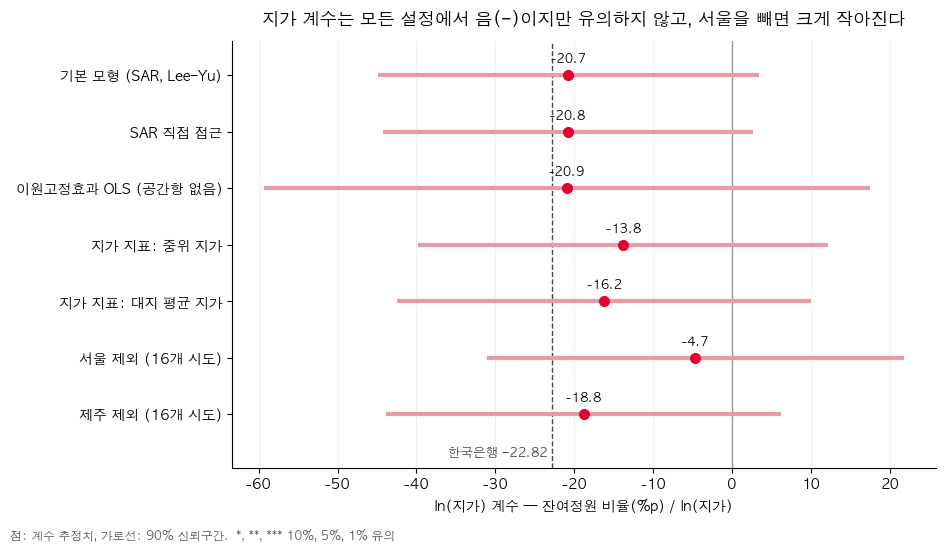

In [9]:
plot = robust.iloc[::-1]
y = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.axvline(0, color="#999999", linewidth=1)
ax.axvline(BOK["ln_평균_지가"][0], color="#444444", linestyle="--", linewidth=1)
ax.text(BOK["ln_평균_지가"][0], -0.75, "한국은행 −22.82 ", fontsize=9, color="#444444", ha="right")
ax.errorbar(plot["계수"], y, xerr=Z90 * plot["표준오차"], fmt="o", color=LAND_COLOR,
            ecolor="#E89AA6", elinewidth=3, capsize=0, markersize=7, zorder=3)
for i, (_, row) in enumerate(plot.iterrows()):
    ax.annotate(f"{row['계수']:.1f}{stars(row['p'])}", (row["계수"], i), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(plot.index)
ax.set_ylim(-0.95, len(plot) - 0.4)
ax.set_xlabel("ln(지가) 계수 — 잔여정원 비율(%p) / ln(지가)")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("지가 계수는 모든 설정에서 음(−)이지만 유의하지 않고, 서울을 빼면 크게 작아진다", fontsize=12.5, pad=12)
fig.text(0.01, 0.01, "점: 계수 추정치, 가로선: 90% 신뢰구간.  *, **, *** 10%, 5%, 1% 유의", fontsize=8.5, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "시도별_강건성.png", dpi=200, bbox_inches="tight")
plt.show()

### 8. 해석

In [10]:
seoul = panel.loc[panel["시도"].eq("서울")].set_index("연도")
no_seoul = robust.loc["서울 제외 (16개 시도)"]
ols_row = robust.loc["이원고정효과 OLS (공간항 없음)"]
ln_land = panel.pivot(index="연도", columns="시도", values="ln_평균_지가")
within_sd = two_way_demean(ln_land.to_numpy()).std(ddof=1)
land_growth = (ln_land.loc[YEARS[-1]] - ln_land.loc[YEARS[0]]).sort_values(ascending=False)
direct_row = robust.loc["SAR 직접 접근"]
coef_range = robust["계수"]

display(Markdown(f"""
- **방향은 한국은행과 같고 크기도 비슷하다.** 17개 시도 × 7년 패널에서 ln(지가) 계수는 **{land_coef['계수']:.2f}**로, 한국은행 시군구 추정치(−22.82)와 거의 같다. 지가가 10% 높으면 잔여정원 비율이 약 {abs(land_coef['계수']) * np.log(1.1):.1f}%p 낮다는 뜻이다.
- **다만 통계적으로 유의하지 않다**(p = {land_coef['p']:.2f}). 관측치가 2,061개에서 119개로 줄어 표준오차가 {land_coef['표준오차']:.1f}로 한국은행(4.2)의 3배를 넘는다. 시도·연도 고정효과를 넣었으므로 계수는 '같은 시도 안에서 지가가 전국 흐름보다 더 오른 해에 잔여정원 비율이 더 낮아졌는가'를 본다. 이렇게 고정효과를 뺀 ln(지가)의 표준편차는 {within_sd:.3f}로 전체 표준편차({panel['ln_평균_지가'].std():.2f})의 {within_sd / panel['ln_평균_지가'].std() * 100:.0f}%에 불과해, 계수를 정밀하게 추정할 만한 변동이 적다.
- **지가 계수는 서울에 크게 기댄다.** 서울을 빼면 계수가 {no_seoul['계수']:.1f}(p = {no_seoul['p']:.2f})로 줄어든다. 2018~2024년 ln(지가) 상승 폭은 {land_growth.index[0]}({land_growth.iloc[0]:.2f})·{land_growth.index[1]}({land_growth.iloc[1]:.2f})이 가장 커서, 서울의 시간 변화가 추정에 큰 몫을 한다.
- **인접 지역 효과는 유의하다.** λ = {rho['계수']:.3f}(p = {rho['p']:.3f})로, 인접 시도의 잔여정원 비율이 10%p 낮으면 해당 시도도 {rho['계수'] * 10:.1f}%p 낮다. 한국은행(1.2%p)보다 크다. 시도 단위에서도 이웃한 지역끼리 빈자리 사정이 함께 움직인다.
- **설정을 바꿔도 지가 계수의 부호는 모두 음(−)이지만**({coef_range.max():.1f} ~ {coef_range.min():.1f}), 어느 설정에서도 10% 수준에서 유의하지 않다. 공간항을 뺀 OLS({ols_row['계수']:.1f}, p = {ols_row['p']:.2f})와 직접 접근({direct_row['계수']:.1f}, p = {direct_row['p']:.2f})은 기본 모형과 크기가 비슷하고, 중위·대지 평균 지가를 쓰면 −14 ~ −16 수준으로 작아진다.
- 통제변수 중 시설 종사자 수만 유의하게 양(+)이고(한국은행과 같은 방향), 65세 이상 인구 비율(−)과 요양병원 수(+)는 방향만 한국은행과 같다.
- 서울의 잔여정원 비율은 {seoul.loc[2018, '잔여정원_비율']:.1f}%(2018) → {seoul.loc[2024, '잔여정원_비율']:.1f}%(2024)로 7년 내내 17개 시도 중 가장 낮다. 고정효과 모형은 이 '수준 차이'를 시도 고정효과로 흡수하므로, 서울이 가장 비싸고 가장 빠듯하다는 사실은 위 계수에 반영되지 않는다.
"""))


- **방향은 한국은행과 같고 크기도 비슷하다.** 17개 시도 × 7년 패널에서 ln(지가) 계수는 **-20.74**로, 한국은행 시군구 추정치(−22.82)와 거의 같다. 지가가 10% 높으면 잔여정원 비율이 약 2.0%p 낮다는 뜻이다.
- **다만 통계적으로 유의하지 않다**(p = 0.16). 관측치가 2,061개에서 119개로 줄어 표준오차가 14.7로 한국은행(4.2)의 3배를 넘는다. 시도·연도 고정효과를 넣었으므로 계수는 '같은 시도 안에서 지가가 전국 흐름보다 더 오른 해에 잔여정원 비율이 더 낮아졌는가'를 본다. 이렇게 고정효과를 뺀 ln(지가)의 표준편차는 0.031로 전체 표준편차(1.17)의 3%에 불과해, 계수를 정밀하게 추정할 만한 변동이 적다.
- **지가 계수는 서울에 크게 기댄다.** 서울을 빼면 계수가 -4.7(p = 0.77)로 줄어든다. 2018~2024년 ln(지가) 상승 폭은 세종(0.31)·서울(0.31)이 가장 커서, 서울의 시간 변화가 추정에 큰 몫을 한다.
- **인접 지역 효과는 유의하다.** λ = 0.270(p = 0.010)로, 인접 시도의 잔여정원 비율이 10%p 낮으면 해당 시도도 2.7%p 낮다. 한국은행(1.2%p)보다 크다. 시도 단위에서도 이웃한 지역끼리 빈자리 사정이 함께 움직인다.
- **설정을 바꿔도 지가 계수의 부호는 모두 음(−)이지만**(-4.7 ~ -20.9), 어느 설정에서도 10% 수준에서 유의하지 않다. 공간항을 뺀 OLS(-20.9, p = 0.37)와 직접 접근(-20.8, p = 0.15)은 기본 모형과 크기가 비슷하고, 중위·대지 평균 지가를 쓰면 −14 ~ −16 수준으로 작아진다.
- 통제변수 중 시설 종사자 수만 유의하게 양(+)이고(한국은행과 같은 방향), 65세 이상 인구 비율(−)과 요양병원 수(+)는 방향만 한국은행과 같다.
- 서울의 잔여정원 비율은 2.8%(2018) → 6.1%(2024)로 7년 내내 17개 시도 중 가장 낮다. 고정효과 모형은 이 '수준 차이'를 시도 고정효과로 흡수하므로, 서울이 가장 비싸고 가장 빠듯하다는 사실은 위 계수에 반영되지 않는다.


### 해석상 주의

- **시도 단위로는 검정력이 낮다.** 한국은행과 같은 모형을 쓰더라도 관측치가 119개뿐이어서 '지가가 잔여정원을 유의하게 줄인다'고 쓸 근거는 되지 못한다. 서울을 빼면 계수도 크게 작아진다(7절). 보고서에서는 '시도 단위에서도 같은 방향·비슷한 크기의 계수가 추정되며, 이는 주로 서울의 변화에서 나온다'는 보조 근거로 쓰고, 유의한 근거는 한국은행의 시군구 추정치를 인용하는 것이 안전하다.
- **고정효과 모형은 지역 간 수준 차이가 아니라 시도 안의 시간 변화를 본다.** 서울처럼 처음부터 지가가 높고 빈자리가 적은 지역의 차이는 시도 고정효과에 흡수된다.
- **인과로 해석하려면 한국은행과 같은 가정이 필요하다.** 시간에 따라 변하면서 지가와 잔여정원에 함께 영향을 주는 요인(예: 지역 개발, 인구 유입)이 통제변수에 없으면 계수가 치우칠 수 있다.
- **변수 정의가 일부 다르다.** 65세 이상 인구는 '단위인구 당'을 총인구 대비 비율로 해석했고, 종사자 수는 시설급여 장기요양기관의 전문인력(요양보호사·간호인력 등) 합계를 썼다. 정원·현원은 보건복지부 집계(연말)라 국민건강보험공단 시설별 현황(월별)과 수치가 조금 다르다.
- 잔여정원 비율의 분모(1~2등급 인정자)는 한국은행 분석과 같은 대리지표이며, 생애말기 고령인구와 수준이 다르다.

In [11]:
# 핵심 수치 검증
assert len(panel) == 119 and panel["잔여정원_비율"].between(0, 100).all()
assert (panel.groupby("연도")["잔여정원_비율"].idxmin().map(panel["시도"]) == "서울").all()
assert round(land_coef["계수"], 2) == -20.74 and land_coef["p"] > 0.1
assert round(rho["계수"], 3) == 0.270 and rho["p"] < 0.05
assert (robust["계수"] < 0).all() and (robust["p"] > 0.1).all()
assert robust.loc["서울 제외 (16개 시도)", "계수"] > -10
print("검증 통과")

검증 통과


### 9. 시각화: 잔여정원 비율과 지가

왼쪽은 17개 시도의 실제 수준을 2018→2024년 궤적으로 그린 것이다. 시도 간 차이(서울이 가장 비싸고 가장 빠듯함)가 보인다. 오른쪽은 통제변수와 시도·연도 고정효과를 걸러낸 뒤 남은 변동이다. 고정효과 모형의 지가 계수는 이 변동으로 추정되며, 회귀선 기울기는 7절의 이원고정효과 OLS 계수와 같다.

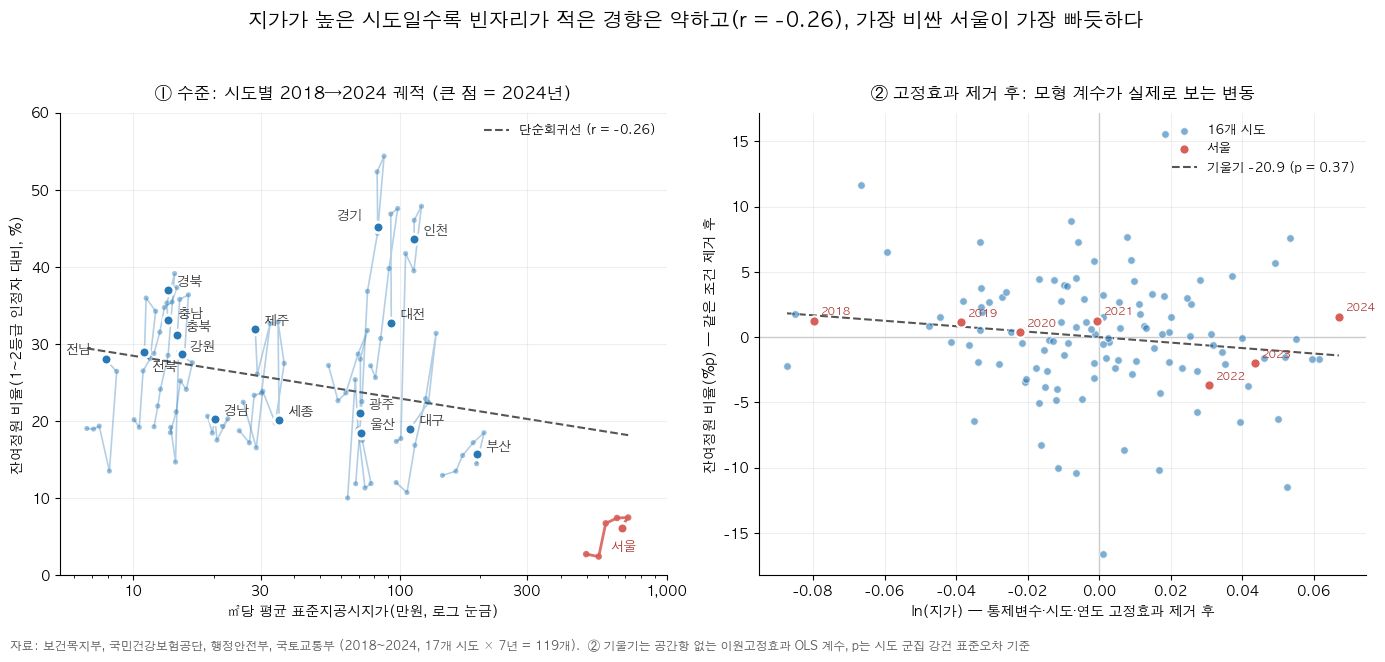

In [12]:
SEOUL_COLOR, OTHER_COLOR, FIT_COLOR = "#D95F59", "#2878B5", "#555555"

# 고정효과·통제변수를 제거한 잔차(Frisch–Waugh–Lovell): 두 잔차의 회귀 기울기 = 이원고정효과 OLS 계수
fe_terms = f"{' + '.join(CONTROLS)} + C(시도) + C(연도)"
partial = panel[["연도", "시도"]].copy()
partial["잔여정원_잔차"] = smf.ols(f"잔여정원_비율 ~ {fe_terms}", data=panel).fit().resid
partial["지가_잔차"] = smf.ols(f"ln_평균_지가 ~ {fe_terms}", data=panel).fit().resid
fwl = smf.ols("잔여정원_잔차 ~ 지가_잔차", data=partial).fit()
assert np.isclose(fwl.params["지가_잔차"], ols_row["계수"])

pooled = smf.ols("잔여정원_비율 ~ ln_평균_지가", data=panel).fit()
pooled_r = np.corrcoef(panel["ln_평균_지가"], panel["잔여정원_비율"])[0, 1]

LEVEL_OFFSET = {"전남": (-30, 4), "전북": (5, -13), "경기": (-30, 5), "서울": (-8, -16), "충남": (7, 2)}

fig, (ax_level, ax_within) = plt.subplots(1, 2, figsize=(14, 6.5))

# (왼쪽) 수준: 시도별 2018→2024 궤적
for name, g in panel.groupby("시도"):
    g = g.sort_values("연도")
    is_seoul = name == "서울"
    color = SEOUL_COLOR if is_seoul else OTHER_COLOR
    ax_level.plot(g["평균_지가"] / 1e4, g["잔여정원_비율"], color=color,
                  alpha=0.9 if is_seoul else 0.35, linewidth=2 if is_seoul else 1.2, zorder=2)
    ax_level.scatter(g["평균_지가"] / 1e4, g["잔여정원_비율"], s=14 if not is_seoul else 22,
                     color=color, alpha=0.9 if is_seoul else 0.45, edgecolor="none", zorder=3)
    last = g.iloc[-1]
    ax_level.scatter(last["평균_지가"] / 1e4, last["잔여정원_비율"], s=60, color=color,
                     edgecolor="white", linewidth=2, zorder=4)
    ax_level.annotate(name, (last["평균_지가"] / 1e4, last["잔여정원_비율"]), xytext=LEVEL_OFFSET.get(name, (6, 3)),
                      textcoords="offset points", fontsize=9.5,
                      color="#B03A35" if is_seoul else "#333333", fontweight="bold" if is_seoul else "normal")
x_line = np.linspace(panel["ln_평균_지가"].min(), panel["ln_평균_지가"].max(), 100)
ax_level.plot(np.exp(x_line) / 1e4, pooled.params["Intercept"] + pooled.params["ln_평균_지가"] * x_line,
              color=FIT_COLOR, linestyle="--", linewidth=1.5, zorder=1, label=f"단순회귀선 (r = {pooled_r:.2f})")
ax_level.set_xscale("log")
ax_level.set_xticks([10, 30, 100, 300, 1000])
ax_level.set_xticklabels(["10", "30", "100", "300", "1,000"])
ax_level.set_xlabel("㎡당 평균 표준지공시지가(만원, 로그 눈금)")
ax_level.set_ylabel("잔여정원 비율(1~2등급 인정자 대비, %)")
ax_level.set_ylim(0, 60)
ax_level.set_title("① 수준: 시도별 2018→2024 궤적 (큰 점 = 2024년)", fontsize=12, pad=10)
ax_level.legend(loc="upper right", frameon=False, fontsize=9)

# (오른쪽) 고정효과 제거 후
is_seoul = partial["시도"].eq("서울")
ax_within.axhline(0, color="#CCCCCC", linewidth=1)
ax_within.axvline(0, color="#CCCCCC", linewidth=1)
ax_within.scatter(partial.loc[~is_seoul, "지가_잔차"], partial.loc[~is_seoul, "잔여정원_잔차"],
                  s=30, color=OTHER_COLOR, alpha=0.6, edgecolor="white", linewidth=0.8, label="16개 시도", zorder=3)
ax_within.scatter(partial.loc[is_seoul, "지가_잔차"], partial.loc[is_seoul, "잔여정원_잔차"],
                  s=55, color=SEOUL_COLOR, edgecolor="white", linewidth=1.5, label="서울", zorder=4)
for _, row in partial.loc[is_seoul].iterrows():
    ax_within.annotate(str(row["연도"]), (row["지가_잔차"], row["잔여정원_잔차"]), xytext=(5, 4),
                       textcoords="offset points", fontsize=8, color="#B03A35")
xr = np.linspace(partial["지가_잔차"].min(), partial["지가_잔차"].max(), 50)
ax_within.plot(xr, fwl.params["Intercept"] + fwl.params["지가_잔차"] * xr, color=FIT_COLOR,
               linestyle="--", linewidth=1.5, label=f"기울기 {fwl.params['지가_잔차']:.1f} (p = {ols_row['p']:.2f})")
ax_within.set_xlabel("ln(지가) — 통제변수·시도·연도 고정효과 제거 후")
ax_within.set_ylabel("잔여정원 비율(%p) — 같은 조건 제거 후")
ax_within.set_title("② 고정효과 제거 후: 모형 계수가 실제로 보는 변동", fontsize=12, pad=10)
ax_within.legend(loc="upper right", frameon=False, fontsize=9)

for ax in (ax_level, ax_within):
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"지가가 높은 시도일수록 빈자리가 적은 경향은 약하고(r = {pooled_r:.2f}), 가장 비싼 서울이 가장 빠듯하다",
             fontsize=14.5, y=0.99)
fig.text(0.01, 0.005,
         "자료: 보건복지부, 국민건강보험공단, 행정안전부, 국토교통부 (2018~2024, 17개 시도 × 7년 = 119개).  "
         "② 기울기는 공간항 없는 이원고정효과 OLS 계수, p는 시도 군집 강건 표준오차 기준",
         fontsize=8.5, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(OUTPUT_DIR / "시도별_잔여정원_지가_산점도.png", dpi=200, bbox_inches="tight")
plt.show()

### 출처

- 한국은행 이슈노트 [제2026-5호] 초고령사회와 생애말기 필수산업의 활성화 — 그림 3.2, 별첨 2 [표 1.1]·[표 1.2]
- 보건복지부_노인복지 생활시설 수 및 생활자 현황_시설 종류별_시도별: https://www.data.go.kr/data/15068616/fileData.do
- 보건복지부_병원 및 의원 수_의료기관 종류별_시도별: https://www.data.go.kr/data/15127855/fileData.do
- 국토교통부_표준지공시지가(2018~2024 이력 파일): https://www.data.go.kr/data/15004246/fileData.do
- KOSIS 국민건강보험공단 '시·도별 등급별 연령별 자격별 등급 판정 현황'(DT_35006_N036), '시·군·구별 장기요양기관 인력 현황'(DT_35006_N022)
- KOSIS 행정안전부 '행정구역(읍면동)별/5세별 주민등록인구'(DT_1B04005N)
- Lee, L. F. & Yu, J. (2010). Estimation of spatial autoregressive panel data models with fixed effects. *Journal of Econometrics*, 154(2), 165–185.